# Result analysis

In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import importlib
import analysis_functions
importlib.reload(analysis_functions)
from analysis_functions import load_case, compute_errors, print_err_mean_std, err_kde_plot, time_kde_plot, err_pointwise_plot, print_exec_times, plot_velocity, compute_errors_for_case

# plt.rcParams.update({
#     "text.usetex": True,
#     "font.family": "serif",
#     "font.serif": ["Computer Modern Roman"],
#     "axes.labelsize": 12,
#     "font.size": 12,
#     "legend.fontsize": 10,
#     "xtick.labelsize": 10,
#     "ytick.labelsize": 10,
# })

In [2]:
RESULT_DIR = "./results/2026-03-19_11_16"

results = load_case(RESULT_DIR)
# case_cylinder_big = load_case(RESULT_DIR, "cylinder_big")

## Errors computation

## Analysis / Visualizations

## Global Errors

#### L1 Norm

In [3]:
errors = compute_errors(results, norm="1")
print_err_mean_std(errors)

numeric divergence = 0.0659793666621514 +- 1.4790281517791772

u poisson error = 0.04059325743804621 +- 0.03016554064561184
p poisson error = 0.23731093835797704 +- 0.21214164984899783
poisson divergence error = 0.0776884210271904 +- 1.5600717235170194

u full error = 0.21484511362788417 +- 0.04556291114820243
p full error = 0.5880521059281997 +- 0.11827383104331086
full divergence error = 0.18963186083841485 +- 6.276004611488308


#### L2 Norm

In [4]:
errors = compute_errors(results, norm="2")
print_err_mean_std(errors)

numeric divergence = 0.0659793666621514 +- 1.4790281517791772

u poisson error = 0.04868554207785423 +- 0.03467681981384898
p poisson error = 0.15879144873556048 +- 0.14176825134390247
poisson divergence error = 0.0776884210271904 +- 1.5600717235170194

u full error = 0.21797662938547982 +- 0.049446300550883594
p full error = 0.5310636914330614 +- 0.20268043599264346
full divergence error = 0.18963186083841485 +- 6.276004611488308


#### Infinity Norm

In [5]:
errors = compute_errors(results, norm="inf")
print_err_mean_std(errors)

numeric divergence = 0.0659793666621514 +- 1.4790281517791772

u poisson error = 0.06936408728258672 +- 0.0412962860776846
p poisson error = 0.1535804095038009 +- 0.10559359991116193
poisson divergence error = 0.0776884210271904 +- 1.5600717235170194

u full error = 0.3343261398100416 +- 0.07761546586500968
p full error = 0.49036267112472326 +- 0.09890321732760102
full divergence error = 0.18963186083841485 +- 6.276004611488308


### Comparison plot

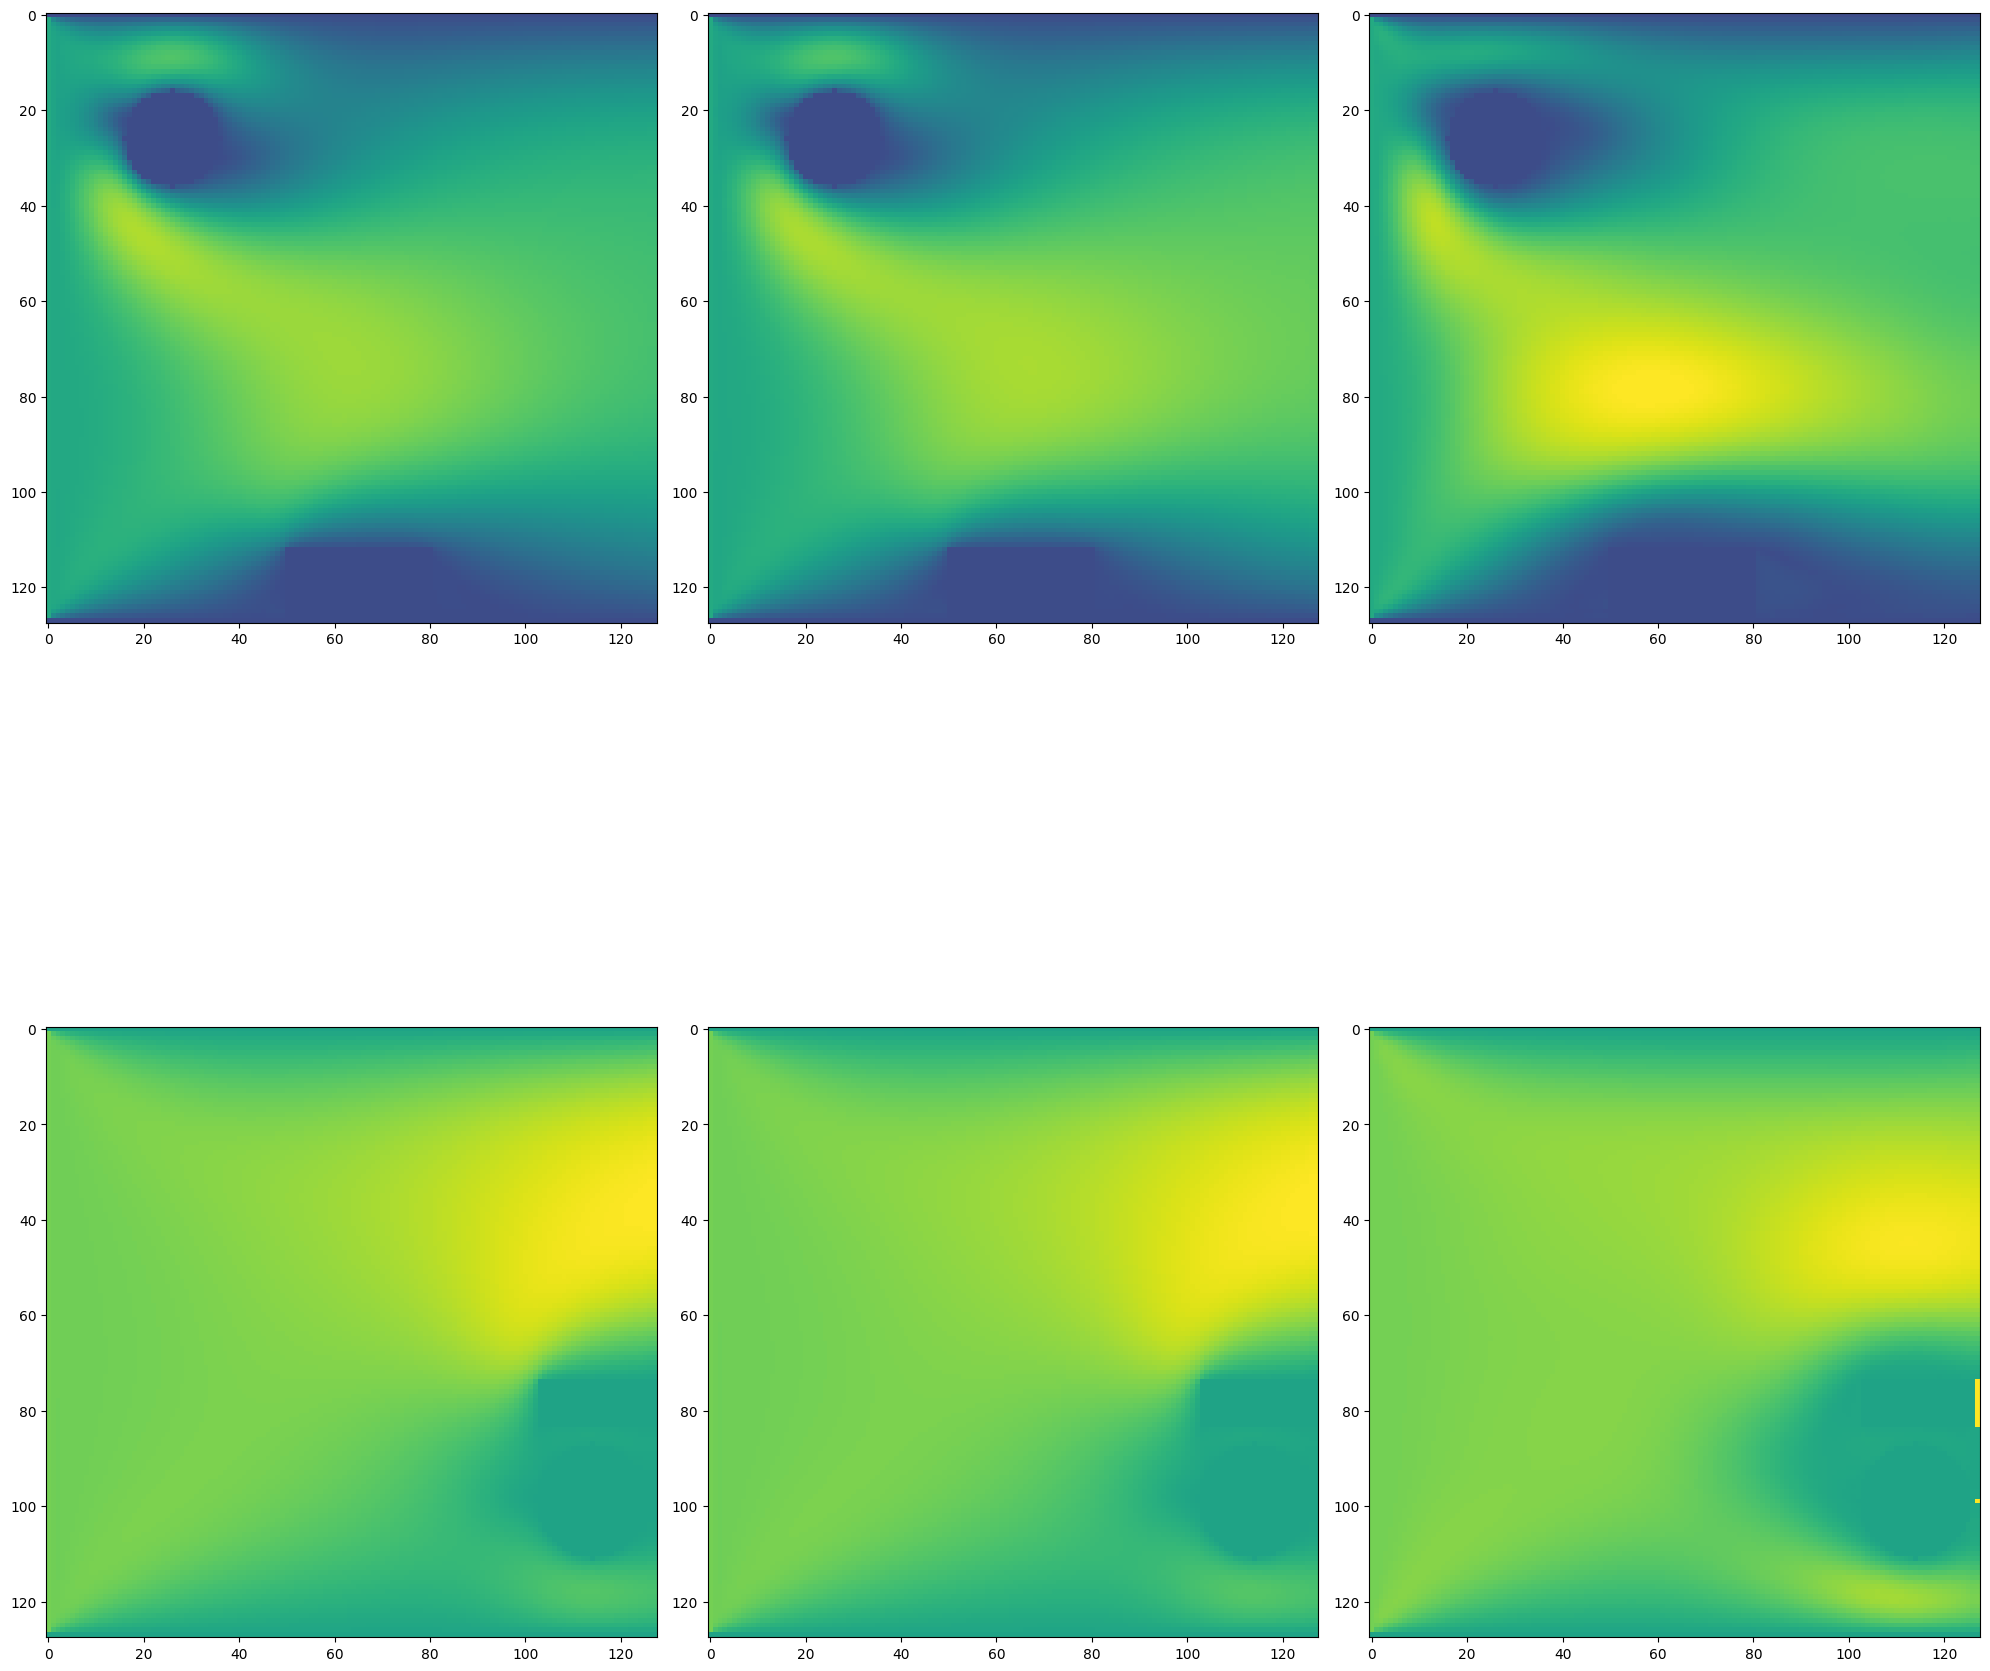

In [6]:
# n_cases = len(results["u_numeric"])
n_cases = 2

fig, ax = plt.subplots(figsize=(20, 12 * n_cases), nrows=n_cases, ncols=3)

for i in range(n_cases):
    Un = np.array(results["u_numeric"][i][:, :, 0], dtype=float)
    Vn = np.array(results["u_numeric"][i][:, :, 1], dtype=float)

    Up = np.array(results["u_poisson"][i][:, :, 0], dtype=float)
    Vp = np.array(results["u_poisson"][i][:, :, 1], dtype=float)

    Uf = np.array(results["u_full"][i][:, :, 0], dtype=float)
    Vf = np.array(results["u_full"][i][:, :, 1], dtype=float)

    height, width = np.shape(results["u_numeric"][i])[0], np.shape(results["u_numeric"][i])[1]
    X, Y = np.meshgrid(np.linspace(0, width, width) + 0.5, 
                       np.linspace(0, height, height) + 0.5)
    

    mag_max = max(
        np.sqrt(Un**2 + Vn**2).max(),
        np.sqrt(Up**2 + Vp**2).max(),
        np.sqrt(Uf**2 + Vf**2).max()
    )

    scale_val = mag_max * 0.3

    vmin = np.min([Un.min(), Vn.min(), Up.min(), Vp.min(), Uf.min(), Vf.min()])
    vmax = np.max([Un.max(), Vn.max(), Up.max(), Vp.max(), Uf.max(), Vf.max()])

    ax[i, 0].imshow(np.sqrt(Un ** 2 + Vn ** 2), vmin=vmin, vmax=vmax)
    ax[i, 1].imshow(np.sqrt(Up ** 2 + Vp ** 2), vmin=vmin, vmax=vmax)
    ax[i, 2].imshow(np.sqrt(Uf ** 2 + Vf ** 2), vmin=vmin, vmax=vmax)

    # plot_velocity(ax[i, 0], Un, Vn, color="red", title="Numeric", scale=10)

    # plot_velocity(ax[i, 1], Up, Vp, color="black", title="Poisson")
    # plot_velocity(ax[i, 1], Un, Vn, color="red", title="Poisson")

    # plot_velocity(ax[i, 2], Uf, Vf, color="black", title="Full")
    # plot_velocity(ax[i, 2], Un, Vn, color="red", title="Full")

    # ax[i, 0].quiver(X, Y, Un, Vn, color="red", alpha = 1, scale=scale_val, scale_units='xy')
    # ax[i, 0].set_aspect('equal', adjustable='box')
    # ax[i, 0].set_title("Numeric")

    # ax[i, 1].quiver(X, Y, Up, Vp, color="black", alpha = 1, scale=scale_val, scale_units='xy')
    # ax[i, 1].quiver(X, Y, Un, Vn, color="red", alpha = 0.8, scale=scale_val, scale_units='xy')
    # ax[i, 1].set_aspect('equal', adjustable='box')
    # ax[i, 1].set_title("Poisson")

    # ax[i, 2].quiver(X, Y, Uf, Vf, color="black", alpha = 1, scale=scale_val, scale_units='xy')
    # ax[i, 2].quiver(X, Y, Un, Vn, color="red", alpha = 0.8, scale=scale_val, scale_units='xy')
    # ax[i, 2].set_aspect('equal', adjustable='box')
    # ax[i, 2].set_title("Full")

plt.tight_layout()

### Pointwise errors

#### L1 Norm

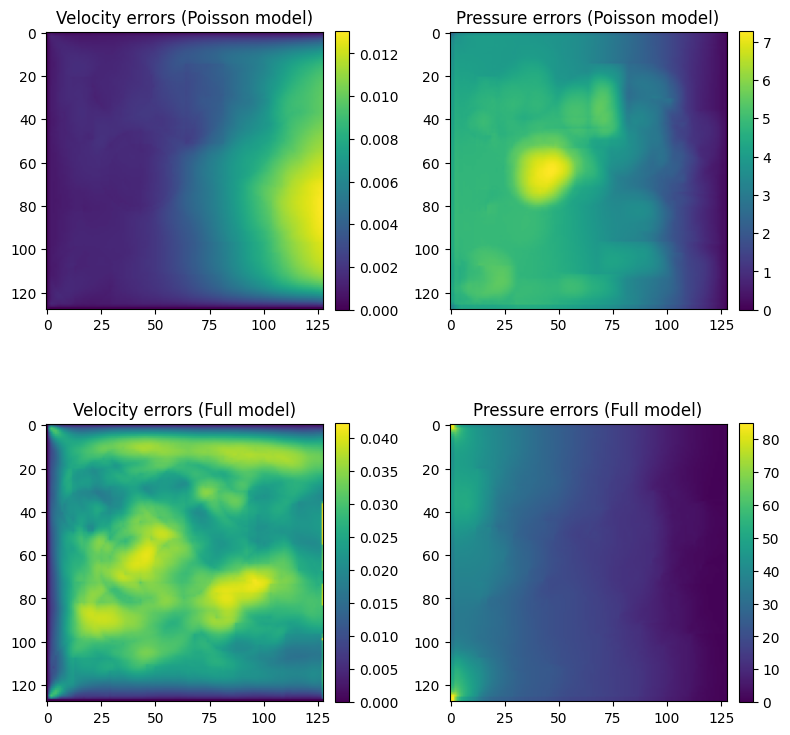

In [7]:
errors = compute_errors(results, norm="1")
err_pointwise_plot(errors)

#### L2 Norm

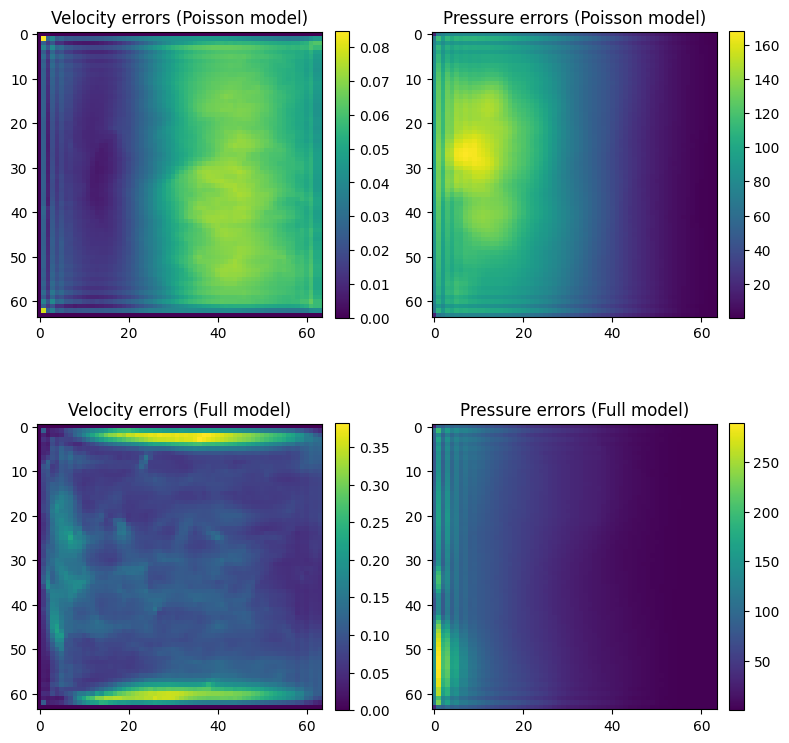

In [59]:
errors = compute_errors(results, norm="2")
err_pointwise_plot(errors)

#### Infinity Norm

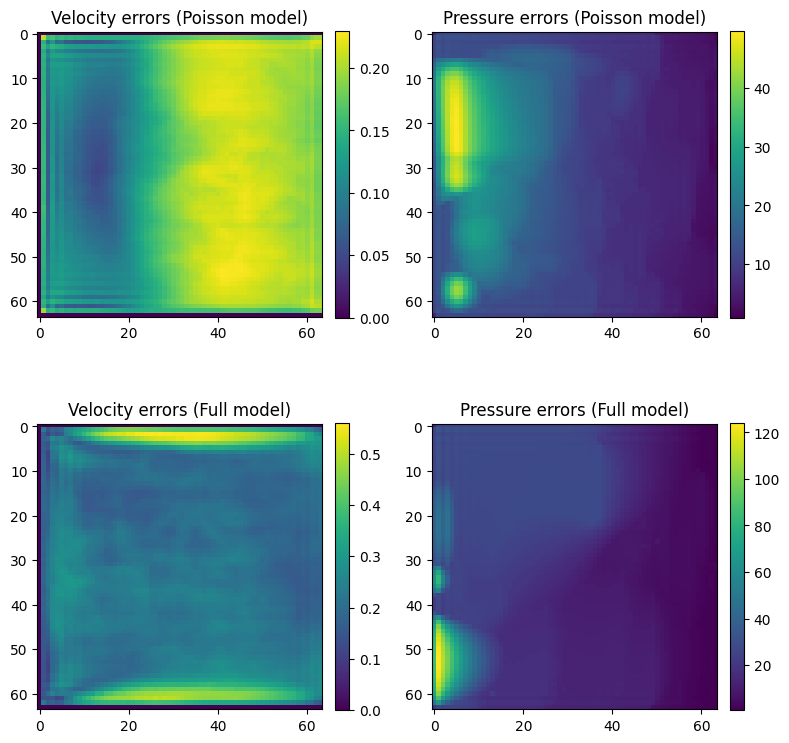

In [60]:
errors = compute_errors(results, norm="inf")
err_pointwise_plot(errors)

### Single case errors

#### L1 norm

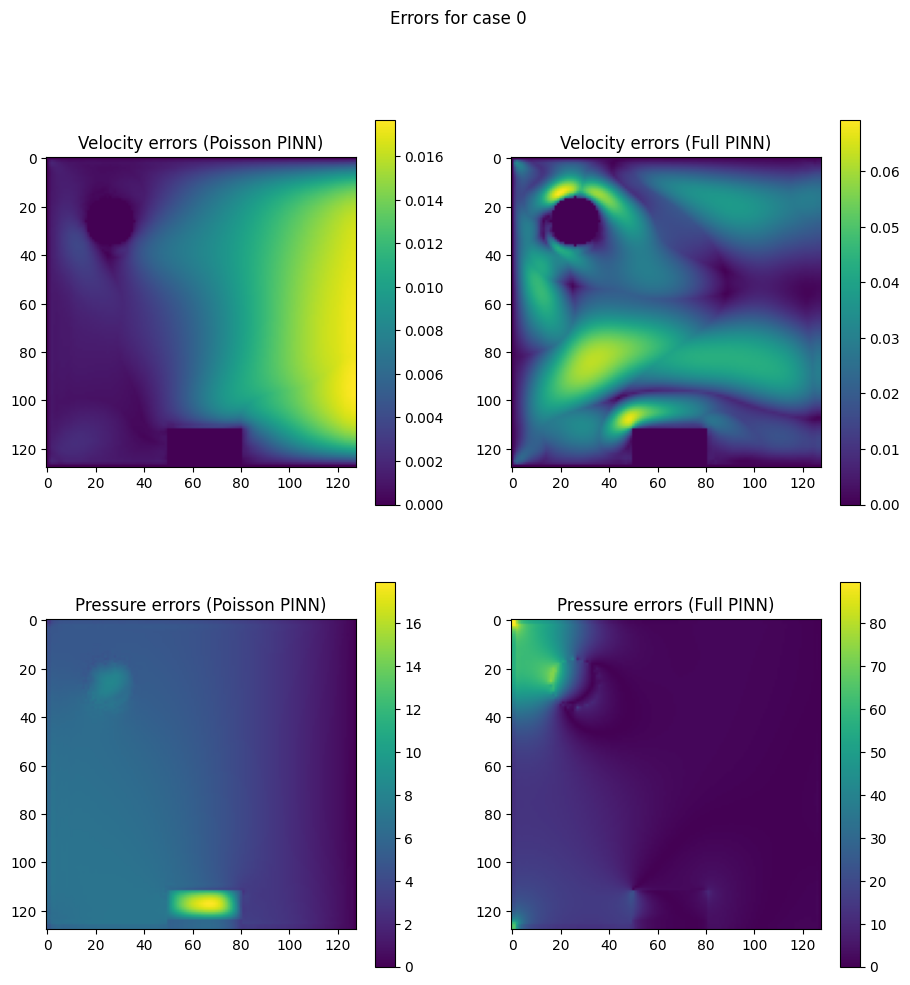

In [8]:
case_num = 0

errors = compute_errors_for_case(results, case_num=case_num, norm="1")

fig, ax = plt.subplots(figsize=(11, 11), nrows=2, ncols=2)
ax = ax.flatten()

im0 = ax[0].imshow(errors["u_pointwise_poisson"].astype(float))
im1 = ax[1].imshow(errors["u_pointwise_full"].astype(float))
im2 = ax[2].imshow(errors["p_pointwise_poisson"].astype(float))
im3 = ax[3].imshow(errors["p_pointwise_full"].astype(float))

ax[0].set_title("Velocity errors (Poisson PINN)")
ax[1].set_title("Velocity errors (Full PINN)")
ax[2].set_title("Pressure errors (Poisson PINN)")
ax[3].set_title("Pressure errors (Full PINN)")

plt.colorbar(im0)
plt.colorbar(im1)
plt.colorbar(im2)
plt.colorbar(im3)

plt.suptitle(f"Errors for case {case_num}")
plt.show()

### Histogram of errors

In [10]:
errors_poisson = np.array([])
errors_full = np.array([])

for case_num in range(0, 100):
    err = compute_errors_for_case(results, case_num=case_num, norm="1")

    boundary = results["boundaries"][case_num]

    err_poisson = err["u_pointwise_poisson"].astype(float)[boundary != 1]
    err_full = err["u_pointwise_full"].astype(float)[boundary != 1]

    errors_poisson = np.concatenate([errors_poisson, err_poisson.flatten()])
    errors_full = np.concatenate([errors_full, err_full.flatten()])

# errors = np.array(errors)

fig, ax = plt.subplots(figsize=(12, 4), nrows=1, ncols=2)
ax[0].hist(errors_poisson, color="black", bins=100)
ax[1].hist(errors_full, color="black", bins=100)

ax[0].set_title("Poisson PINN")
ax[1].set_title("Navier-Stokes PINN")
plt.show()

IndexError: index 25 is out of bounds for axis 0 with size 25